In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

data **load**

In [2]:
df = sns.load_dataset("tips")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
df.shape

(244, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [5]:
df.duplicated().sum()

np.int64(1)

In [6]:
df.drop_duplicates(inplace=True)

In [7]:
df.isnull().sum()

,0
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


In [8]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

**Numerical columns**

In [9]:
df.describe()

,total_bill,tip,size
count,243.000000,243.000000,243.000000
mean,19.813868,3.002387,2.572016
std,8.910071,1.385002,0.952356
min,3.070000,1.000000,1.000000
25%,13.380000,2.000000,2.000000
50%,17.810000,2.920000,2.000000
75%,24.175000,3.575000,3.000000
max,50.810000,10.000000,6.000000


**Categorical columns**

In [10]:
df['sex'].unique()

['Female', 'Male']
Categories (2, object): ['Male', 'Female']

In [11]:
df['smoker'].unique()

['No', 'Yes']
Categories (2, object): ['Yes', 'No']

In [12]:
df['day'].unique()

['Sun', 'Sat', 'Thur', 'Fri']
Categories (4, object): ['Thur', 'Fri', 'Sat', 'Sun']

In [13]:
df['time'].unique()

['Dinner', 'Lunch']
Categories (2, object): ['Lunch', 'Dinner']

In [14]:
df['sex'].value_counts()


,count
sex,
Male,157
Female,86


In [15]:
df['smoker'].value_counts()

,count
smoker,
No,151
Yes,92


In [16]:
df['day'].value_counts()

,count
day,
Sat,87
Sun,76
Thur,61
Fri,19


In [17]:
df['time'].value_counts()

,count
time,
Dinner,176
Lunch,67


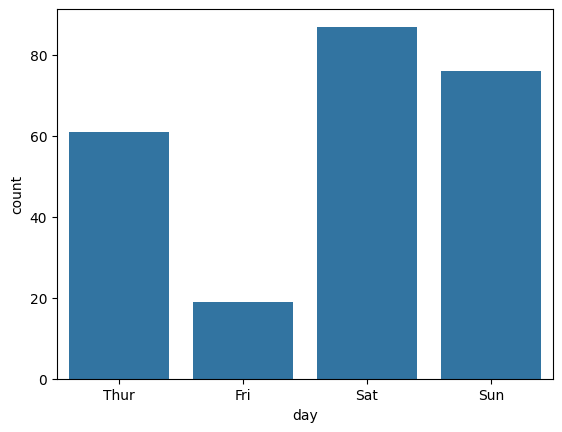

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(data=df,x='day')
plt.show()

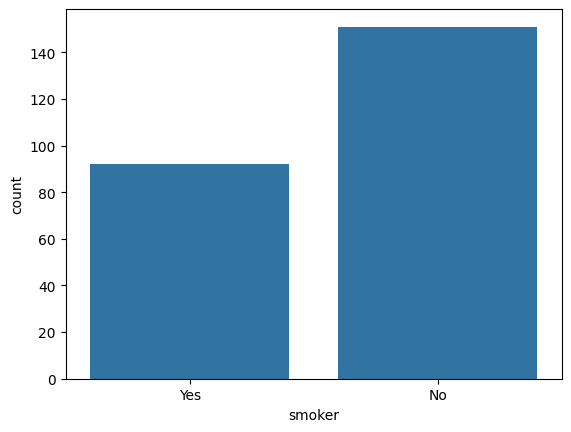

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df,x = 'smoker')
plt.show()

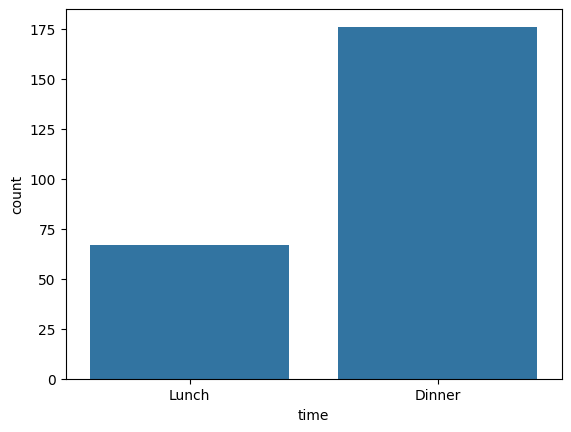

In [20]:
sns.countplot(data=df,x = 'time')
plt.show()

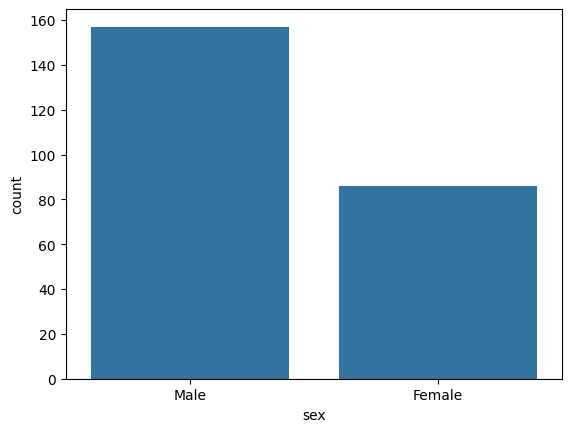

In [21]:
sns.countplot(data=df,x = 'sex')
plt.show()

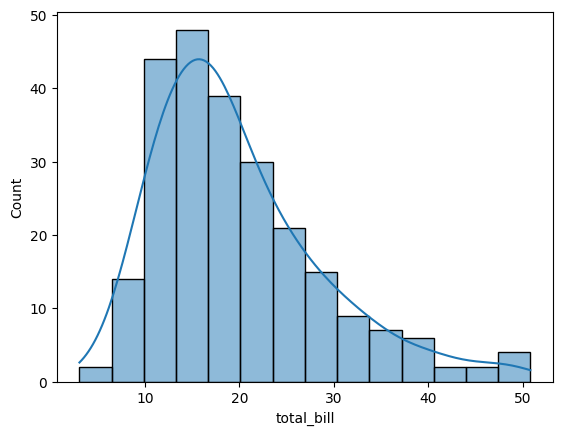

In [22]:
sns.histplot(data=df,x='total_bill',kde = True)
plt.show()

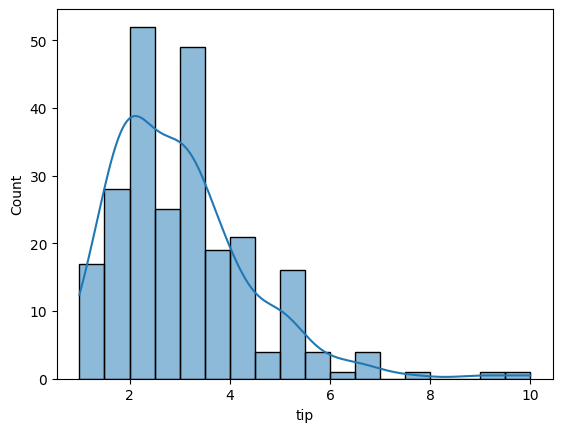

In [23]:
sns.histplot(data=df,x='tip',kde = True)
plt.show()

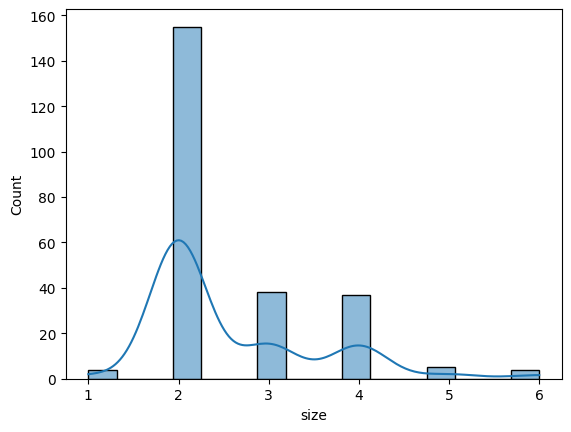

In [24]:
sns.histplot(data=df,x='size',kde = True)
plt.show()

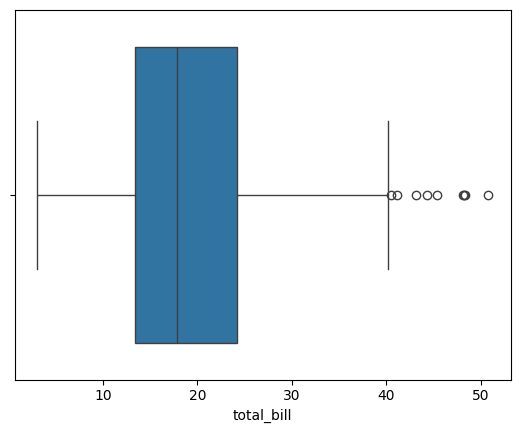

In [25]:
sns.boxplot(data=df,x='total_bill')
plt.show()

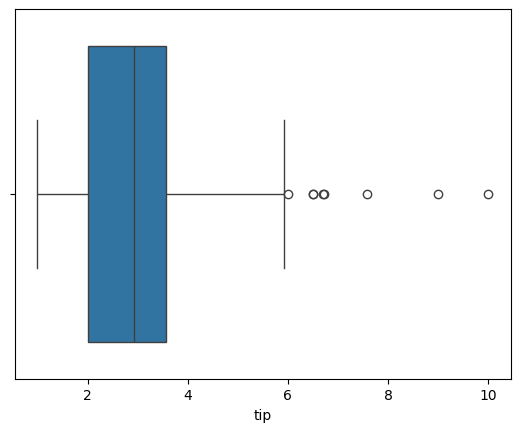

In [26]:
sns.boxplot(data=df,x='tip')
plt.show()

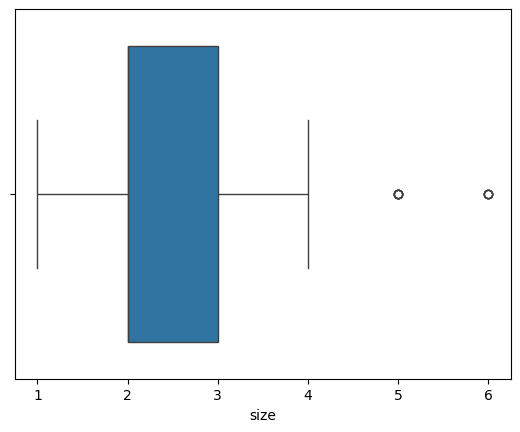

In [27]:
sns.boxplot(data=df,x='size')
plt.show()

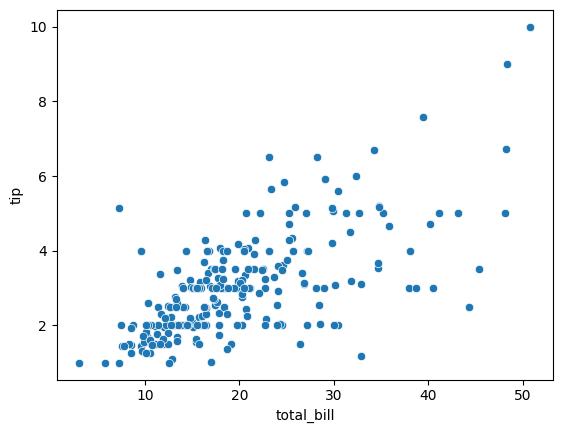

In [28]:
sns.scatterplot(data=df,x='total_bill',y='tip')
plt.show()

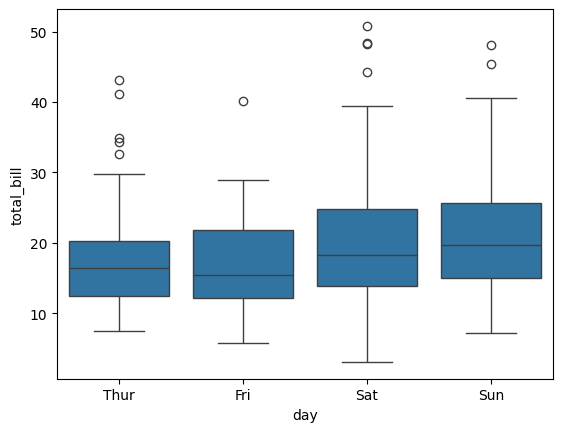

In [29]:
sns.boxplot(data=df,x='day',y='total_bill')
plt.show()

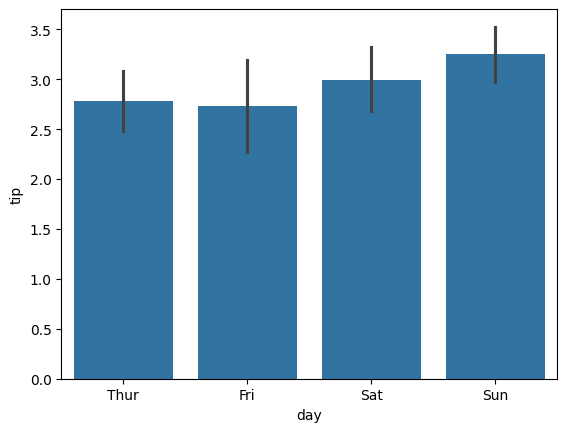

In [30]:
sns.barplot(data=df,x='day',y='tip')
plt.show()

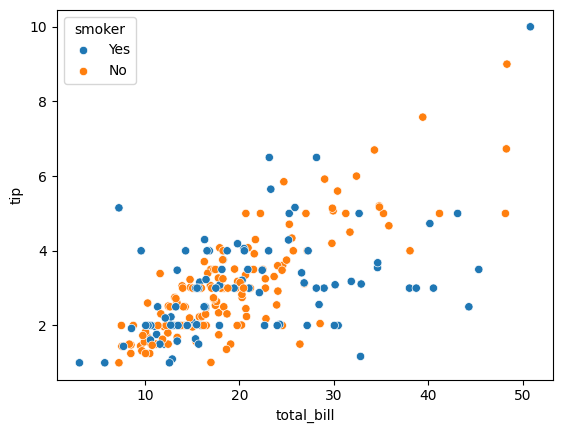

In [31]:
sns.scatterplot(data=df,x='total_bill',y='tip',hue='smoker')
plt.show()

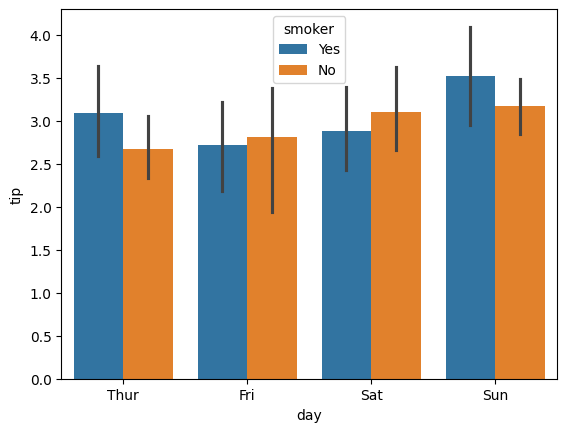

In [32]:
sns.barplot(data=df,x='day',y='tip',hue='smoker')
plt.show()

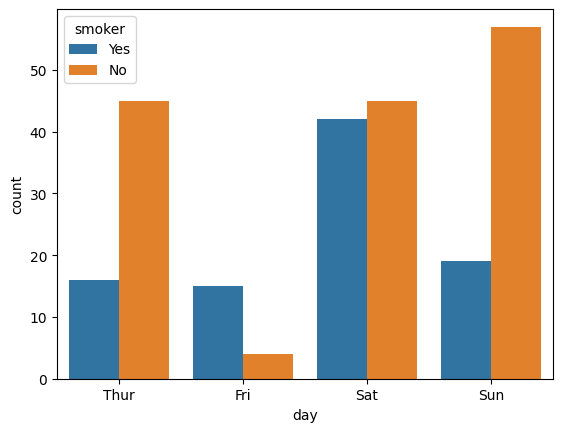

In [33]:
sns.countplot(data=df,x = 'day',hue='smoker')
plt.show()

In [34]:
df.corr(numeric_only=True)

,total_bill,tip,size
total_bill,1.000000,0.674998,0.597589
tip,0.674998,1.000000,0.488400
size,0.597589,0.488400,1.000000


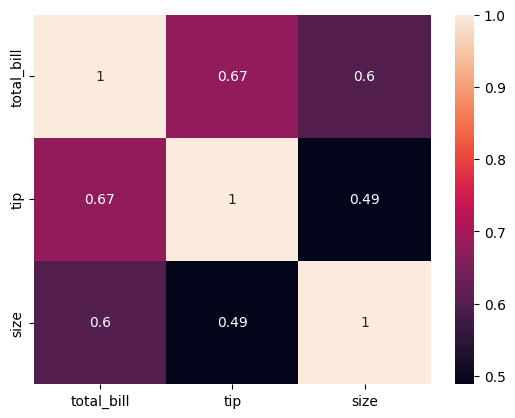

In [35]:
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

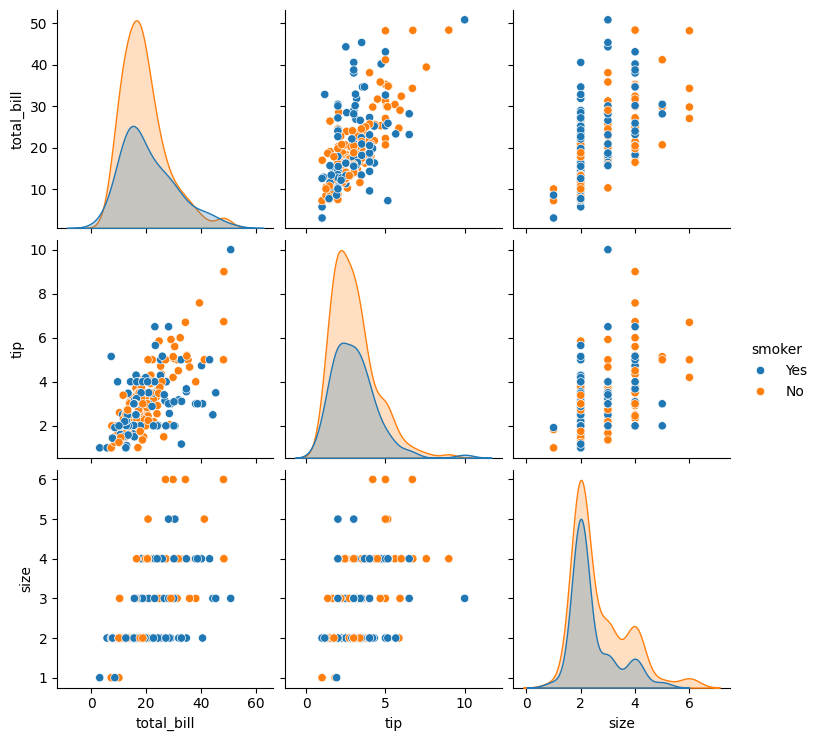

In [36]:
sns.pairplot(df,hue='smoker')
plt.show()

Q1. tips dataset me kis din avg tip sabse jyda hai?**bold text**

In [37]:
df.groupby('day')['tip'].mean().sort_values(ascending=False)

,tip
day,
Sun,3.255132
Sat,2.993103
Thur,2.784098
Fri,2.734737


Q2 kis din ka avg bill sabse zyda tha?

In [38]:
df.groupby('day')['total_bill'].mean().sort_values(ascending=False)

,total_bill
day,
Sun,21.410000
Sat,20.441379
Thur,17.759508
Fri,17.151579


In [39]:
df.pivot_table(
    values='tip',
    index='day',
    columns='time',
    aggfunc='mean'
)

time,Lunch,Dinner
day,,
Thur,2.780500,3.000000
Fri,2.382857,2.940000
Sat,NaN,2.993103
Sun,NaN,3.255132


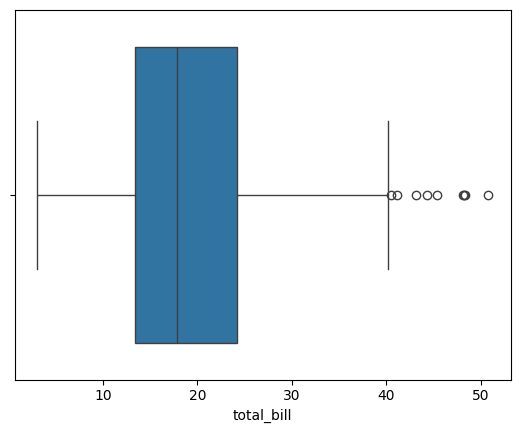

In [40]:
sns.boxplot(data=df,x='total_bill')
plt.show()

**outliers count using Z-score methods  **

In [41]:
from scipy import stats
z = stats.zscore(df['total_bill'])
outliers = df[abs(z) > 3]
print(outliers)


     total_bill    tip   sex smoker  day    time  size
59        48.27   6.73  Male     No  Sat  Dinner     4
156       48.17   5.00  Male     No  Sun  Dinner     6
170       50.81  10.00  Male    Yes  Sat  Dinner     3
212       48.33   9.00  Male     No  Sat  Dinner     4


In [42]:
df['total_bill'].corr(df['tip'])

np.float64(0.6749978565456075)

In [43]:
df['size'].corr(df['tip'])

np.float64(0.488400394674884)

**EDA summary**

In [44]:
print(df[['total_bill','tip']].mean()) # avg bill aur tip

total_bill    19.813868
tip            3.002387
dtype: float64


In [45]:
print(df['day'].value_counts()) # sabse zayda records kis day ke hai

day
Sat     87
Sun     76
Thur    61
Fri     19
Name: count, dtype: int64


In [46]:
print(df.groupby('time')['tip'].mean()) # avg tip kis time zyada hai

time
Lunch     2.738955
Dinner    3.102670
Name: tip, dtype: float64


**Features selection**

In [47]:
X = df[['total_bill','size']] # feature select

In [48]:
y = df['tip'] # target select

In [49]:
print(X.shape)
print(y.shape)

(243, 2)
(243,)


**Train test split**

In [50]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training data:",X_train.shape)
print("Testing data:",X_test.shape)

Training data: (194, 2)
Testing data: (49, 2)


**LinearRegression model**

In [51]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [52]:
y_pred = model.predict(X_test)
print(y_pred[:5])

[2.88015155 1.9482666  2.89245407 2.11693356 3.88505913]


In [53]:
import pandas as pd
comparison = pd.DataFrame({
    'Actual Tip': y_test.values,
    'Predicted Tip': y_pred
})
print(comparison)

    Actual Tip  Predicted Tip
0         3.18       2.880152
1         2.00       1.948267
2         2.74       2.892454
3         1.47       2.116934
4         5.92       3.885059
5         3.11       3.983233
6         3.00       4.267238
7         2.50       2.395234
8         3.23       2.455111
9         2.55       3.228449
10        3.00       2.751121
11        2.00       3.971923
12        2.72       2.328611
13       10.00       5.721842
14        1.83       1.829704
15        2.50       2.276324
16        1.17       3.977330
17        3.92       3.028578
18        2.47       2.595948
19        2.00       2.433184
20        2.45       3.409914
21        3.35       3.178345
22        3.76       2.746905
23        1.45       2.014047
24        5.00       3.638110
25        3.00       2.685341
26        1.71       2.074767
27        5.00       3.340612
28        4.30       2.584984
29        5.14       4.410605
30        1.00       1.591883
31        1.44       1.861403
32        

**Mean Absolute Error**

In [54]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error:",mae)

Mean Absolute Error: 0.7666932211421317


**R2 Score**

In [55]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)
print("R2 Score:",r2)

R2 Score: 0.5217749320928373


**Feature Coefficients**

In [56]:
print("Features:",
X.columns.tolist())
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Features: ['total_bill', 'size']
Coefficients: [0.08433348 0.22819623]
Intercept: 0.752269527519005


**Final Results**

In [57]:
print("MAE:",mae)
print("R2 Score:",r2)
print("\nAverage Actual Tip:",
y_test.mean())
print("Average Predicted Tip:",
y_pred.mean())

MAE: 0.7666932211421317
R2 Score: 0.5217749320928373

Average Actual Tip: 2.8732653061224496
Average Predicted Tip: 2.9118458423316063


In [58]:
print("PROJECT SUMMARY")
print("----------------")
print("Dataset: Tips")
print("ML Model: Linear Regression")
print("Features: total_bill, size")
print("Target: tip")
print(f"MAE: {mae:.2f}")
print(f"R2 Score: {r2:.2f}")

PROJECT SUMMARY
----------------
Dataset: Tips
ML Model: Linear Regression
Features: total_bill, size
Target: tip
MAE: 0.77
R2 Score: 0.52


**Logistic Regression model**

In [59]:
import pandas as pd
X = df.drop(columns=['smoker'])
y = df['smoker']

# **Categorical feature to convert dummy variables**.
X = pd.get_dummies(X, drop_first=True, dtype=int)
print(X.head())
print(X.shape)
print(y.value_counts())

   total_bill   tip  size  sex_Female  day_Fri  day_Sat  day_Sun  time_Dinner
0       16.99  1.01     2           1        0        0        1            1
1       10.34  1.66     3           0        0        0        1            1
2       21.01  3.50     3           0        0        0        1            1
3       23.68  3.31     2           0        0        0        1            1
4       24.59  3.61     4           1        0        0        1            1
(243, 8)
smoker
No     151
Yes     92
Name: count, dtype: int64


In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(194, 8)
(49, 8)


In [61]:
from sklearn.linear_model import LogisticRegression
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [62]:
y_pred = model_lr.predict(X_test)
print(y_pred[:10])

['Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']


In [63]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy:", accuracy)
print("Accuracy %:", accuracy * 100)

Accuracy: 0.6530612244897959
Accuracy %: 65.3061224489796


**Confusion Matrix**

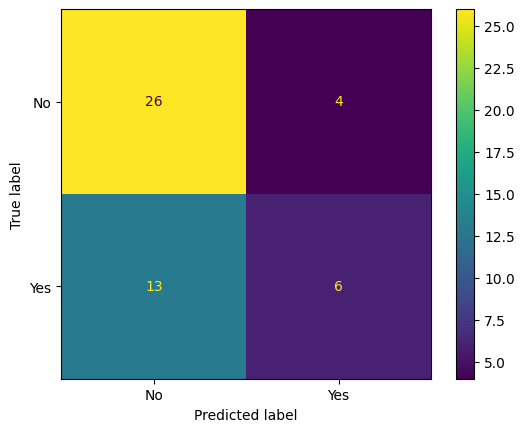

In [64]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model_lr.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model_lr.classes_
)

disp.plot()
plt.show()

In [65]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

          No       0.67      0.87      0.75        30
         Yes       0.60      0.32      0.41        19

    accuracy                           0.65        49
   macro avg       0.63      0.59      0.58        49
weighted avg       0.64      0.65      0.62        49



In [66]:
import pandas as pd
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})
print(comparison.head(15))

    Actual Predicted
21      No       Yes
1       No        No
233     No        No
131     No        No
118     No        No
63     Yes        No
138    Yes        No
206    Yes        No
159     No        No
127     No        No
179    Yes       Yes
201    Yes        No
145     No        No
37      No        No
109    Yes        No


In [67]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model_lr.coef_[0]
})

print(
    coefficients.sort_values(
        by='Coefficient',
        ascending=False
    )
)

       Feature  Coefficient
4      day_Fri     1.710938
5      day_Sat     0.480849
7  time_Dinner     0.202864
0   total_bill     0.060265
3   sex_Female     0.042272
1          tip    -0.081080
6      day_Sun    -0.425117
2         size    -0.505623


**KNN Model**

In [68]:
import pandas as pd

X = df.drop(columns=['smoker'])
y = df['smoker']

X = pd.get_dummies(X, drop_first=True, dtype=int)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [69]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)


Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])

In [70]:
y_pred_knn = knn_model.predict(X_test)
print("Predictions:")
print(y_pred_knn[:10])

Predictions:
['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']


In [71]:
from sklearn.metrics import accuracy_score
knn_accuracy = accuracy_score(y_test, y_pred)
print("KNN Accuracy:", knn_accuracy)
print("KNN Accuracy(%):", round(knn_accuracy * 100, 2))

KNN Accuracy: 0.6530612244897959
KNN Accuracy(%): 65.31


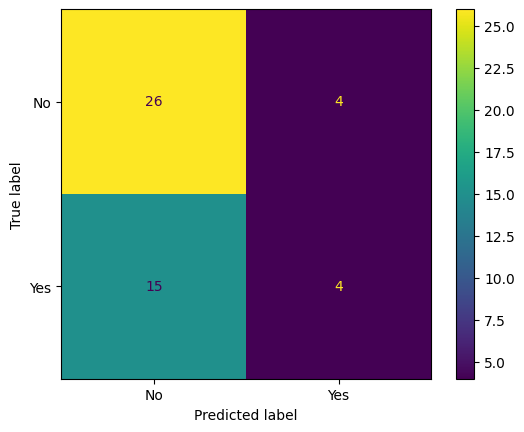

In [72]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn,
    labels=knn_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=knn_model.classes_
)

disp.plot()
plt.show()

In [73]:
from sklearn.metrics import classification_report
print(classification_report(
    y_test,
    y_pred_knn,
    zero_division=0
))

              precision    recall  f1-score   support

          No       0.63      0.87      0.73        30
         Yes       0.50      0.21      0.30        19

    accuracy                           0.61        49
   macro avg       0.57      0.54      0.51        49
weighted avg       0.58      0.61      0.56        49



In [74]:
import pandas as pd
comparison_knn = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_knn
})
print(comparison_knn.head(15))

    Actual Predicted
21      No        No
1       No        No
233     No        No
131     No        No
118     No        No
63     Yes        No
138    Yes        No
206    Yes        No
159     No        No
127     No        No
179    Yes        No
201    Yes        No
145     No        No
37      No        No
109    Yes        No


In [75]:
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

k_results = []

for k in range(1, 16):
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    k_results.append({
        'K': k,
        'Accuracy': accuracy_score(y_test, pred)
    })

k_results = pd.DataFrame(k_results)

print(k_results.sort_values(
    'Accuracy',
    ascending=False
))

     K  Accuracy
14  15  0.653061
5    6  0.632653
1    2  0.632653
6    7  0.632653
11  12  0.632653
7    8  0.632653
3    4  0.632653
13  14  0.632653
12  13  0.632653
2    3  0.612245
4    5  0.612245
8    9  0.612245
10  11  0.612245
9   10  0.612245
0    1  0.591837


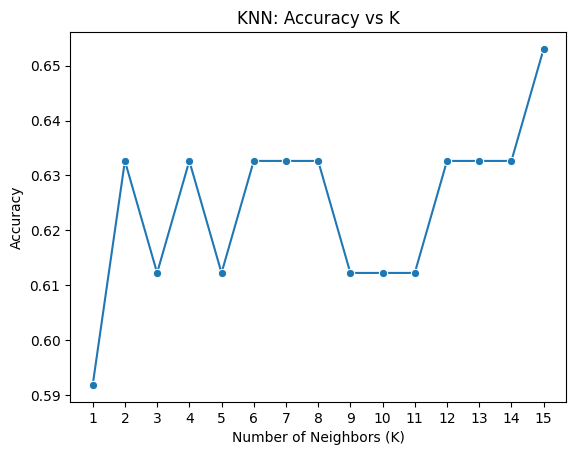

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.lineplot(
    data=k_results,
    x='K',
    y='Accuracy',
    marker='o'
)

plt.title('KNN: Accuracy vs K')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.xticks(range(1, 16))
plt.show()

**Comparesion of two models logistic & knn**

In [77]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

results = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1 Score': f1_score(
            y_test, y_pred,
            pos_label='Yes',
            zero_division=0
        )
    },
    {
        'Model': 'KNN',
        'Accuracy': accuracy_score(y_test, y_pred_knn),
        'F1 Score': f1_score(
            y_test, y_pred_knn,
            pos_label='Yes',
            zero_division=0
        )
    }
])

print(results.sort_values('Accuracy', ascending=False))

                 Model  Accuracy  F1 Score
0  Logistic Regression  0.653061  0.413793
1                  KNN  0.612245  0.296296


***Naive Bayes model***

In [78]:
from sklearn.naive_bayes import GaussianNB
model_nb = GaussianNB()
model_nb.fit(X_train, y_train)

GaussianNB()

In [80]:
from sklearn.metrics import accuracy_score
y_pred_nb = model_nb.predict(X_test)
nb_accuracy = accuracy_score(y_test, y_pred_nb)
print("Naive Bayes Accuracy:", nb_accuracy)
print("Accuracy % :", round(nb_accuracy * 100, 2 ))

Naive Bayes Accuracy: 0.6326530612244898
Accuracy % : 63.27


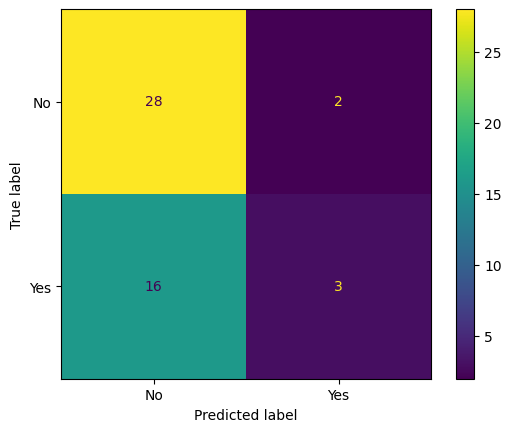

In [84]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=model_nb.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=model_nb.classes_
)

disp.plot()
plt.show()



In [85]:
from sklearn.metrics import classification_report
print(classification_report(
    y_test,
    y_pred_knn,
    zero_division=0
))

              precision    recall  f1-score   support

          No       0.63      0.87      0.73        30
         Yes       0.50      0.21      0.30        19

    accuracy                           0.61        49
   macro avg       0.57      0.54      0.51        49
weighted avg       0.58      0.61      0.56        49



***Comparesion of models logistic & knn, naive bayes***

In [86]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

results = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1 Score': f1_score(
            y_test, y_pred,
            pos_label='Yes',
            zero_division=0
        )
    },
    {
        'Model': 'KNN',
        'Accuracy': accuracy_score(y_test, y_pred_knn),
        'F1 Score': f1_score(
            y_test, y_pred_knn,
            pos_label='Yes',
            zero_division=0
        )
    },
     {
        'Model': 'Naive Bayes',
        'Accuracy': accuracy_score(y_test, y_pred_nb),
        'F1 Score': f1_score(
            y_test, y_pred_nb,
            pos_label='Yes',
            zero_division=0
        )
     }

])

print(results.sort_values('Accuracy', ascending=False))

                 Model  Accuracy  F1 Score
0  Logistic Regression  0.653061  0.413793
2          Naive Bayes  0.632653  0.250000
1                  KNN  0.612245  0.296296


***Decision Tree Model***

In [92]:
from sklearn.tree import DecisionTreeClassifier
model_dt = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model_dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [93]:
from sklearn.metrics import accuracy_score
y_pred_dt = model_dt.predict(X_test)
dt_accuracy = accuracy_score(y_test, y_pred_nb)
print("Dicision Tree Accuracy:", dt_accuracy)
print("Accuracy % :", round(dt_accuracy * 100, 2 ))

Dicision Tree Accuracy: 0.6326530612244898
Accuracy % : 63.27


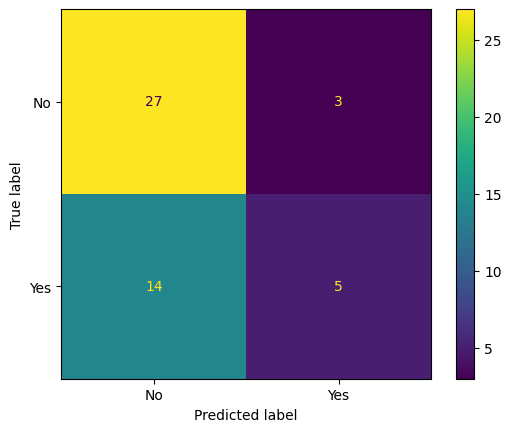

In [94]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=model_dt.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=model_dt.classes_
)

disp.plot()
plt.show()

In [95]:
from sklearn.metrics import classification_report
print(classification_report(
    y_test,
    y_pred_dt,
    zero_division=0
))

              precision    recall  f1-score   support

          No       0.66      0.90      0.76        30
         Yes       0.62      0.26      0.37        19

    accuracy                           0.65        49
   macro avg       0.64      0.58      0.57        49
weighted avg       0.65      0.65      0.61        49



***Visualize of Decision Tree***

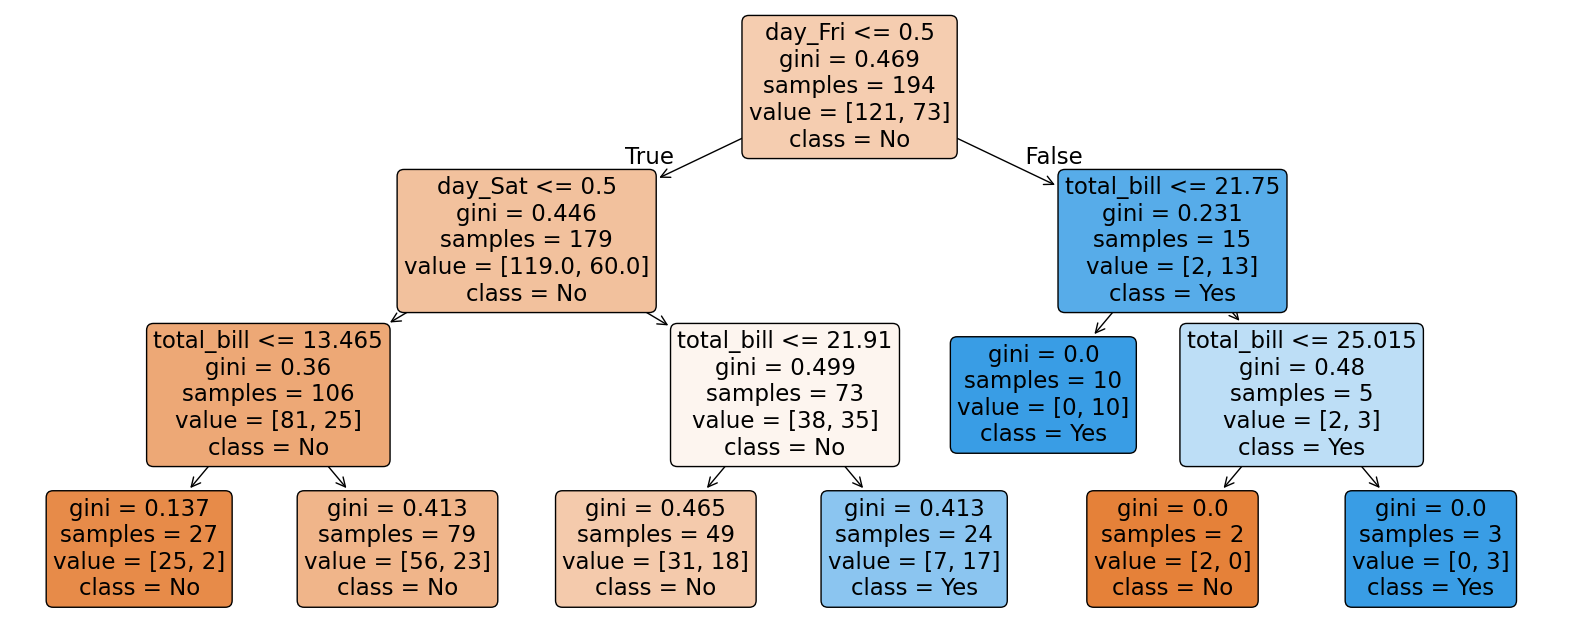

In [98]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 8))

plot_tree(
    model_dt,
    feature_names=X.columns,
    class_names=[str(c) for c in model_dt.classes_],
    filled=True,
    rounded=True
)
plt.show()

***Feature Importance***

In [99]:
import pandas as pd
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model_dt.feature_importances_
})

print(
    importance.sort_values(
        "Importance",
        ascending=False
    )
)

       Feature  Importance
0   total_bill    0.412954
4      day_Fri    0.354453
5      day_Sat    0.232593
1          tip    0.000000
3   sex_Female    0.000000
2         size    0.000000
6      day_Sun    0.000000
7  time_Dinner    0.000000


***Compare of these models***

In [100]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 Score": f1_score(
            y_test, y_pred,
            pos_label="Yes",
            zero_division=0
        )
    },
    {
        "Model": "KNN",
        "Accuracy": accuracy_score(y_test, y_pred_knn),
        "F1 Score": f1_score(
            y_test, y_pred_knn,
            pos_label="Yes",
            zero_division=0
        )
    },
    {
        "Model": "Naive Bayes",
        "Accuracy": accuracy_score(y_test, y_pred_nb),
        "F1 Score": f1_score(
            y_test, y_pred_nb,
            pos_label="Yes",
            zero_division=0
        )
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, y_pred_dt),
        "F1 Score": f1_score(
            y_test, y_pred_dt,
            pos_label="Yes",
            zero_division=0
        )
    }
])

print(results.sort_values("Accuracy", ascending=False))

                 Model  Accuracy  F1 Score
0  Logistic Regression  0.653061  0.413793
3        Decision Tree  0.653061  0.370370
2          Naive Bayes  0.632653  0.250000
1                  KNN  0.612245  0.296296


***Suppot Vector Machine Model***

In [102]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
model_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf'))
])

model_svm.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('svm', SVC())])

In [104]:
from sklearn.metrics import accuracy_score
y_pred_svm = model_svm.predict(X_test)
svm_accuracy = accuracy_score(y_test, y_pred_svm)
print("SVM Accuracy:", svm_accuracy)
print("SVM Accuracy % :", round(svm_accuracy * 100, 2 ))

SVM Accuracy: 0.6326530612244898
SVM Accuracy % : 63.27


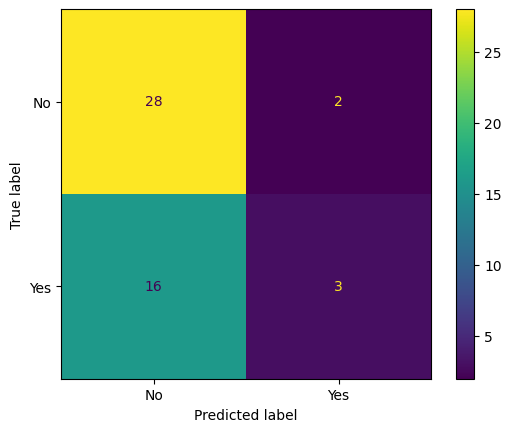

In [105]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=model_svm.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=model_svm.classes_
)

disp.plot()
plt.show()

In [106]:
from sklearn.metrics import classification_report
print(classification_report(
    y_test,
    y_pred_svm,
    zero_division=0
))

              precision    recall  f1-score   support

          No       0.64      0.93      0.76        30
         Yes       0.60      0.16      0.25        19

    accuracy                           0.63        49
   macro avg       0.62      0.55      0.50        49
weighted avg       0.62      0.63      0.56        49



In [107]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 Score": f1_score(
            y_test, y_pred,
            pos_label="Yes",
            zero_division=0
        )
    },
    {
        "Model": "KNN",
        "Accuracy": accuracy_score(y_test, y_pred_knn),
        "F1 Score": f1_score(
            y_test, y_pred_knn,
            pos_label="Yes",
            zero_division=0
        )
    },
    {
        "Model": "Naive Bayes",
        "Accuracy": accuracy_score(y_test, y_pred_nb),
        "F1 Score": f1_score(
            y_test, y_pred_nb,
            pos_label="Yes",
            zero_division=0
        )
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, y_pred_dt),
        "F1 Score": f1_score(
            y_test, y_pred_dt,
            pos_label="Yes",
            zero_division=0
        )
    },
    {
        "Model": "SVM",
        "Accuracy": accuracy_score(y_test, y_pred_svm),
        "F1 Score": f1_score(
            y_test, y_pred_svm,
            pos_label="Yes",
            zero_division=0
        )
    }
])

print(results.sort_values("Accuracy", ascending=False))

                 Model  Accuracy  F1 Score
0  Logistic Regression  0.653061  0.413793
3        Decision Tree  0.653061  0.370370
2          Naive Bayes  0.632653  0.250000
4                  SVM  0.632653  0.250000
1                  KNN  0.612245  0.296296


In [109]:
# 1. Logistic Regression
model_lr.fit(X_train, y_train)

# 2. KNN
knn_model.fit(X_train, y_train)

# 3. Naive Bayes
model_nb.fit(X_train, y_train)

# 4. Decision Tree
model_dt.fit(X_train, y_train)

# 5. SVM
model_svm.fit(X_train, y_train)

print("All 5 models trained successfully!")

All 5 models trained successfully!


***Table of model Comparsion***

In [110]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": model_lr,
    "KNN": knn_model,
    "Naive Bayes": model_nb,
    "Decision Tree": model_dt,
    "SVM": model_svm
}

results = []

for name, model in models.items():
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, pos_label="Yes", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, pos_label="Yes", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1 Score", ascending=False
)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.653,0.600,0.316,0.414
3,Decision Tree,0.653,0.625,0.263,0.370
1,KNN,0.633,0.600,0.158,0.250
2,Naive Bayes,0.633,0.600,0.158,0.250
4,SVM,0.633,0.600,0.158,0.250


***Model Accuracy Graph***

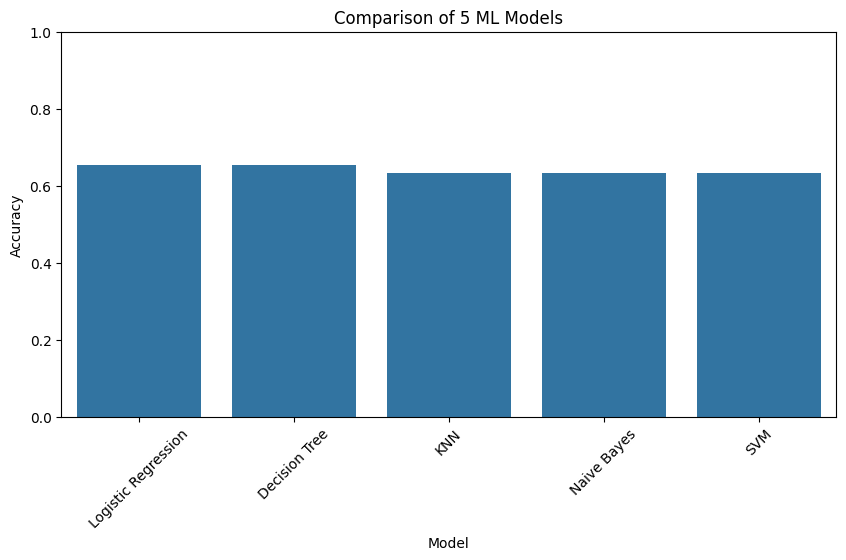

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Comparison of 5 ML Models")
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.show()

***Best Model Confusion Matrix***

Best model: Logistic Regression


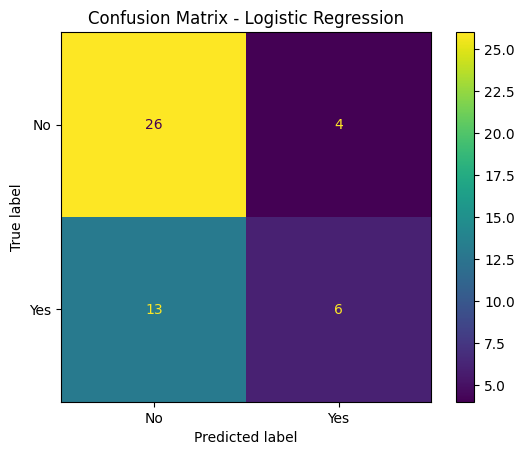

In [112]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model_name = results_df.iloc[0]["Model"]

models = {
    "Logistic Regression": model_lr,
    "KNN": knn_model,
    "Naive Bayes": model_nb,
    "Decision Tree": model_dt,
    "SVM": model_svm
}

best_model = models[best_model_name]
best_pred = best_model.predict(X_test)

print("Best model:", best_model_name)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

***Model Evaluate By Cross-Validation***

In [113]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("CV F1 scores:", cv_scores)
print("Mean CV F1:", cv_scores.mean().round(3))

CV F1 scores: [nan nan nan nan nan]
Mean CV F1: nan


***Best Model Tuning***

In [114]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    "max_depth": [2, 3, 4, 5, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1 macro:", round(grid.best_score_, 3))

Best parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV F1 macro: 0.643


***Tuned Model Evaluate***

Best Parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 10}
Test Accuracy: 0.653

Classification Report:
              precision    recall  f1-score   support

          No       0.66      0.90      0.76        30
         Yes       0.62      0.26      0.37        19

    accuracy                           0.65        49
   macro avg       0.64      0.58      0.57        49
weighted avg       0.65      0.65      0.61        49



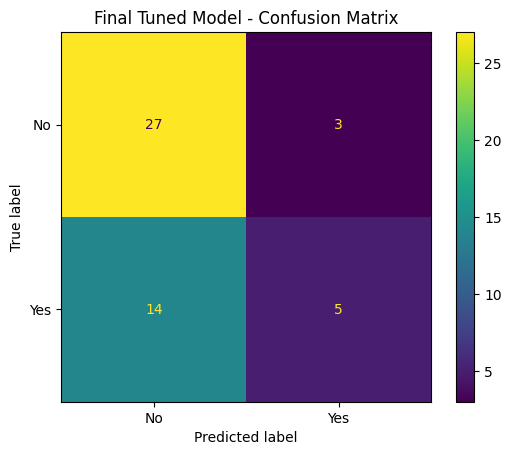

In [115]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_model = grid.best_estimator_

y_pred_final = best_model.predict(X_test)

print("Best Parameters:", grid.best_params_)
print("Test Accuracy:", round(
    accuracy_score(y_test, y_pred_final), 3
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_final
)
plt.title("Final Tuned Model - Confusion Matrix")
plt.show()

In [118]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_final
})

display(comparison.head(10))

,Actual,Predicted
21,No,No
1,No,No
233,No,No
131,No,No
118,No,No
63,Yes,No
138,Yes,No
206,Yes,Yes
159,No,No
127,No,No


In [ ]:
|